<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/ch5_heat_capacity_lin_est.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Estimating heat capacity with a model that is linear in the parameters
(Victor Z and Jaron T, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $X$ (temperature), $Y$ (heat capacity) | `x`, `y` | inputs [K] and outputs [cal/mol-K] |
| $\mathbf{X}=[1,\ x,\ x^2]$, $\mathbf{y}$ | `X`, `y` | data matrix and output vector |
| $\theta=(\theta_0,\theta_1,\theta_2)$ | `theta` (true), `theta_hat` | parameters |
| $\hat{\mathbf{y}}$, $\hat{\epsilon}$ | `y_hat`, `eps_hat` | predictions and residuals |
| $\hat{\sigma}$ | `sigma_hat` | estimated noise SD |
| $\mathrm{Cov}[\hat{\theta}]$, $\mathcal{I}(\theta)$ | `Cov_theta`, `FI` | parameter covariance and Fisher information |

**Note:** This notebook reproduces Examples 5.3 to 5.6 (Section 5.2) of *Statistics for Chemical Engineers*: estimating a quadratic model of heat capacity versus temperature from calorimetry data.

**The concept.** The heat capacity is modeled as $Y=\theta_0+\theta_1X+\theta_2X^2+\epsilon$ with $\epsilon\sim\mathcal{N}(0,\sigma^2)$. Stacking the $S$ experiments gives $\mathbf{y}=\mathbf{X}\theta+\epsilon$ with rows $(1,x_\omega,x_\omega^2)$. Maximizing the likelihood of Gaussian noise is the same as minimizing

$$SSE(\theta)=\frac{1}{2}(\mathbf{y}-\mathbf{X}\theta)^T(\mathbf{y}-\mathbf{X}\theta).$$

The gradient is $\nabla_\theta SSE=-\mathbf{X}^T(\mathbf{y}-\mathbf{X}\theta)$; setting it to zero gives the normal equations $\mathbf{X}^T\mathbf{X}\hat{\theta}=\mathbf{X}^T\mathbf{y}$. The Hessian $\mathbf{X}^T\mathbf{X}$ is the curvature of $SSE$: a sharp minimum means precise estimates.

## Least-squares estimate

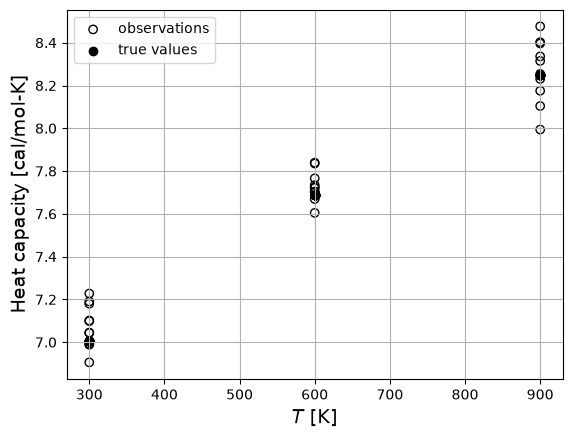

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, probplot

# true model  C_p = theta_0 + theta_1 T + theta_2 T^2  (cal/mol-K, T in K)
theta = np.array([6.190, 2.923e-3, -7.052e-7])

# S = 30 experiments: 10 replicates at each of T = 300, 600, 900 K
x = np.repeat([300.0, 600.0, 900.0], 10)
S = len(x)
X = np.column_stack([np.ones(S), x, x**2])
y_true = X @ theta
np.random.seed(0)        # results differ slightly from Matlab (different random numbers)
sigma = 0.1
y = y_true + np.random.normal(0, sigma, S)

plt.scatter(x, y, facecolors='none', edgecolors='black', label='observations')
plt.scatter(x, y_true, color='black', label='true values')
plt.xlabel('$T$ [K]', fontsize=14)
plt.ylabel('Heat capacity [cal/mol-K]', fontsize=14)
plt.legend()
plt.grid(True)
plt.show()

With $\Sigma=\sigma^2 I$, MLE is SSE minimization:
$\hat{\theta}=(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$. The minimizer is unique if the Hessian
$\nabla^2_\theta SSE=\mathbf{X}^T\mathbf{X}$ is positive definite.

In [2]:
theta_hat = np.linalg.solve(X.T @ X, X.T @ y)
y_hat = X @ theta_hat
eps_hat = y - y_hat
print("theta_hat =", np.array2string(theta_hat, precision=3))
print("eigenvalues of X^T X:", np.array2string(np.linalg.eigvalsh(X.T @ X), precision=3))

theta_hat = [ 6.310e+00  2.747e-03 -6.348e-07]
eigenvalues of X^T X: [5.263e-01 6.980e+05 7.938e+12]


**Check the math.** The residuals $\hat{\epsilon}=\mathbf{y}-\mathbf{X}\hat{\theta}$ are orthogonal to the columns of $\mathbf{X}$ (the gradient is zero). If the model is adequate, they look like a sample of $\mathcal{N}(0,\sigma^2)$.

gradient at theta_hat (relative): [-7.7e-17  1.1e-16 -3.9e-17]


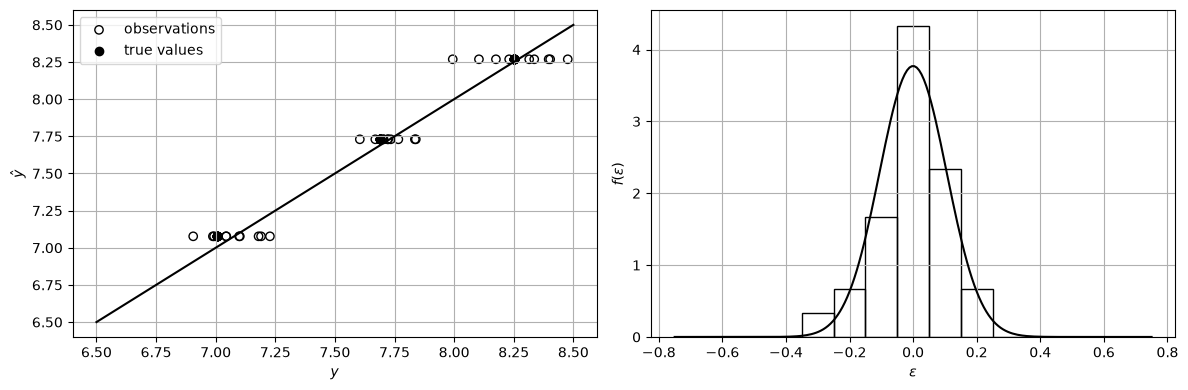

In [3]:
print("gradient at theta_hat (relative):", np.array2string(X.T @ eps_hat / (X.T @ np.abs(y)), precision=1))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot([6.5, 8.5], [6.5, 8.5], 'k')
axs[0].scatter(y, y_hat, facecolors='none', edgecolors='black', label='observations')
axs[0].scatter(y_true, y_hat, color='black', label='true values')
axs[0].set_xlabel('$y$'); axs[0].set_ylabel(r'$\hat{y}$'); axs[0].legend()
e = np.linspace(-0.75, 0.75, 200)
axs[1].hist(eps_hat, bins=np.arange(-0.75, 0.85, 0.1), density=True, edgecolor='black', facecolor='none')
axs[1].plot(e, norm.pdf(e, *norm.fit(eps_hat)), 'k-', linewidth=1.5)
axs[1].set_xlabel(r'$\epsilon$'); axs[1].set_ylabel(r'$f(\epsilon)$')
for ax in axs:
    ax.grid(True)
plt.tight_layout()
plt.show()

## Parameter covariance

Fit $\epsilon\sim\mathcal{N}(\hat{\mu},\hat{\sigma}^2)$ to the residuals and use
$\mathrm{Cov}[\hat{\theta}]=(\mathbf{X}^T\Sigma^{-1}\mathbf{X})^{-1}=(\mathbf{X}^T\mathbf{X})^{-1}\hat{\sigma}^2$.

In [4]:
mu_hat, sigma_hat = norm.fit(eps_hat)
Cov_theta = np.linalg.inv(X.T @ X) * sigma_hat**2
print(f"mu_hat = {mu_hat:.2e},  sigma_hat = {sigma_hat:.3f}")
print("Cov[theta_hat] =\n", np.array2string(Cov_theta, precision=3))

mu_hat = -5.92e-16,  sigma_hat = 0.106
Cov[theta_hat] =
 [[ 2.127e-02 -7.836e-05  6.219e-08]
 [-7.836e-05  3.047e-07 -2.488e-10]
 [ 6.219e-08 -2.488e-10  2.073e-13]]


## Fisher information

For the linear model, $\mathcal{I}(\theta)=\mathbf{X}^T\Sigma^{-1}\mathbf{X}=\mathrm{Cov}[\hat{\theta}]^{-1}$;
large eigenvalues mean the data carry a lot of information.

In [5]:
FI = X.T @ X / sigma_hat**2
print("I(theta) =\n", np.array2string(FI, precision=3))
print("eigenvalues of I:", np.array2string(np.linalg.eigvalsh(FI)[::-1], precision=3))

I(theta) =
 [[2.680e+03 1.608e+06 1.126e+09]
 [1.608e+06 1.126e+09 8.683e+11]
 [1.126e+09 8.683e+11 7.091e+14]]
eigenvalues of I: [7.091e+14 6.235e+07 4.702e+01]


## R^2 and Q-Q plot of the residuals

$S_y=\sum_\omega(y_\omega-\bar{y})^2$, $S_m=\sum_\omega(\hat{y}_\omega-\bar{y})^2$, $S_e=\sum_\omega(y_\omega-\hat{y}_\omega)^2$ and
$R^2=S_m/S_y=1-S_e/S_y$. A Q-Q plot checks whether the residuals are Gaussian.

R^2 = S_m/S_y = 0.9549   (1 - S_e/S_y = 0.9549)


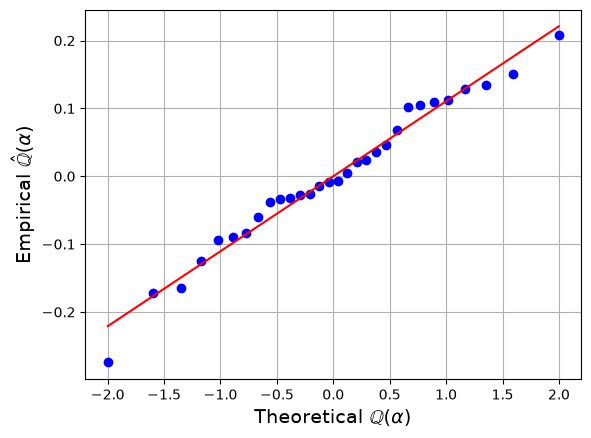

In [6]:
y_bar = np.mean(y)
S_y = np.sum((y - y_bar)**2)
S_m = np.sum((y_hat - y_bar)**2)
S_e = np.sum((y - y_hat)**2)
print(f"R^2 = S_m/S_y = {S_m/S_y:.4f}   (1 - S_e/S_y = {1 - S_e/S_y:.4f})")

probplot(eps_hat, dist="norm", plot=plt)
plt.title('')
plt.xlabel(r'Theoretical $\mathbb{Q}(\alpha)$', fontsize=14)
plt.ylabel(r'Empirical $\hat{\mathbb{Q}}(\alpha)$', fontsize=14)
plt.grid(True)
plt.show()

**Note:** As in the book, the model captures the trend, the residuals are Gaussian (purely random), and the parameter variances are small: the Fisher information shows a sharp minimum and precise estimates.